<a href="https://colab.research.google.com/github/imnotnnurr/Tubes_KecebutB/blob/main/EEG_GA_PSO_LSTM_Fuzzy_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEG Eye-State Intelligent Monitoring (Kelompok 14)
**Pipeline:** Dataset UCI (EEG Eye State) → preprocessing → **GA** (seleksi channel) → **PSO** (hyperparameter LSTM) → **LSTM** → **Fuzzy Mamdani** → artefak untuk dashboard Streamlit.

**Cara pakai**
1. Aktifkan GPU: *Runtime → Change runtime type → T4 GPU*.
2. Jalankan sel dari atas ke bawah. Pertama biarkan `MODE = "QUICK"` (tes cepat, beberapa menit, **bukan hasil laporan**).
3. Kalau semua sel lolos tanpa error, ubah `MODE = "FULL"`, lalu *Runtime → Restart session* dan jalankan ulang dari atas.
4. Hasil tiap tahap disimpan otomatis (`RESUME=True`), jadi kalau sesi putus, jalankan ulang dan tahap yang sudah selesai dilewati (selama runtime belum di-reset).
5. Sel terakhir membuat ZIP hasil untuk diunduh.

In [ ]:
# ===== 1. SETUP & KONFIGURASI =====
!pip -q install ucimlrepo
import os, json, random, time, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

MODE   = "QUICK"      # "QUICK" = tes cepat | "FULL" = hasil untuk laporan
RESUME = True         # lewati tahap yang hasilnya sudah tersimpan
QUICK  = (MODE == "QUICK")
N_RUNS       = 1 if QUICK else 5     # jumlah independent run GA/PSO dan seed model final
EPOCHS_FINAL = 5 if QUICK else 40
GA_P  = dict(pop_size=4 if QUICK else 10, generations=2 if QUICK else 8, crossover_rate=0.8,
             mutation_rate=0.08, tournament_k=3, elitism=1, alpha=0.02,
             seq_len=16, epochs=3 if QUICK else 15, batch_size=64)
PSO_P = dict(n_particles=3 if QUICK else 8, iterations=2 if QUICK else 6, w=0.7, c1=1.5, c2=1.5,
             epochs=3 if QUICK else 15, batch_size=64)
BASE_CFG = dict(seq_len=16, units=32, dropout=0.2, lr=1e-3)    # konfigurasi baseline (Model A)

OUT = Path(f"/content/eeg_out_{MODE.lower()}"); OUT.mkdir(parents=True, exist_ok=True)
print("MODE:", MODE, "| N_RUNS:", N_RUNS, "| OUT:", OUT)
print("GPU:", tf.config.list_physical_devices("GPU"))

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

def cached(name, fn):
    """Jalankan fn() lalu simpan JSON; jika sudah ada dan RESUME, muat dari file."""
    p = OUT / name
    if RESUME and p.exists():
        print(f"[resume] {name} dimuat dari cache"); return json.load(open(p))
    res = fn()
    json.dump(res, open(p, "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return json.load(open(p))

MODE: QUICK | N_RUNS: 1 | OUT: /content/eeg_out_quick
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data: unduh, split kronologis, preprocessing (anti data leakage)

In [ ]:
FEATURES = ["AF3","F7","F3","FC5","T7","P7","O1","O2","P8","T8","FC6","F4","F8","AF4"]
TARGET = "eyeDetection"

def load_data():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=264)
        d = pd.concat([ds.data.features, ds.data.targets], axis=1)
    except Exception as e:
        print("Gagal unduh otomatis:", e, "\nUpload CSV dataset (15 kolom) secara manual:")
        from google.colab import files
        up = files.upload(); d = pd.read_csv(list(up)[0])
    if d.shape[1] == 15:
        d.columns = FEATURES + [TARGET]
    d[TARGET] = d[TARGET].astype(int)
    return d.reset_index(drop=True)

df = load_data()
df.to_csv(OUT / "eeg_eye_state.csv", index=False)       # juga dipakai untuk versi MATLAB
print(df.shape, "| missing:", int(df.isna().sum().sum()))

# split kronologis 70/15/15 (TANPA shuffle)
n = len(df); i1, i2 = int(n*0.70), int(n*0.85)
parts = {"train": df.iloc[:i1], "val": df.iloc[i1:i2], "test": df.iloc[i2:]}

# outlier clipping (IQR) + standardisasi: dihitung HANYA dari train
Xtr = parts["train"][FEATURES]
q1, q3 = Xtr.quantile(0.25), Xtr.quantile(0.75)
LO, HI = q1 - 3*(q3-q1), q3 + 3*(q3-q1)
clip = lambda X: X.clip(LO, HI, axis=1)
MEAN = clip(Xtr).mean()
STD  = clip(Xtr).std(ddof=0).replace(0, 1.0)
XS = {k: ((clip(v[FEATURES]) - MEAN) / STD).values.astype("float32") for k, v in parts.items()}
YS = {k: v[TARGET].values for k, v in parts.items()}

def make_windows(X, y, L):
    idx = np.arange(L-1, len(X))
    return np.stack([X[i-L+1:i+1] for i in idx]).astype("float32"), y[idx]

def get_data(seq_len, idx=None):
    """Window per split (tidak melintasi batas split). idx = indeks channel terpilih."""
    out = {}
    for k in ["train", "val", "test"]:
        X = XS[k] if idx is None else XS[k][:, idx]
        out[k] = make_windows(X, YS[k], seq_len)
    return out
print({k: v.shape for k, v in XS.items()})

(14980, 15) | missing: 0
{'train': (10486, 14), 'val': (2247, 14), 'test': (2247, 14)}


## 3. EDA

                count     mean      std      min      25%      50%      75%  \
AF3           14980.0  4321.92  2492.07  1030.77  4280.51  4294.36  4311.79   
F7            14980.0  4009.77    45.94  2830.77  3990.77  4005.64  4023.08   
F3            14980.0  4264.02    44.43  1040.00  4250.26  4262.56  4270.77   
FC5           14980.0  4164.95  5216.40  2453.33  4108.21  4120.51  4132.31   
T7            14980.0  4341.74    34.74  2089.74  4331.79  4338.97  4347.18   
P7            14980.0  4644.02  2924.79  2768.21  4611.79  4617.95  4626.67   
O1            14980.0  4110.40  4600.93  2086.15  4057.95  4070.26  4083.59   
O2            14980.0  4616.06    29.29  4567.18  4604.62  4613.33  4624.10   
P8            14980.0  4218.83  2136.41  1357.95  4190.77  4199.49  4209.23   
T8            14980.0  4231.32    38.05  1816.41  4220.51  4229.23  4239.49   
FC6           14980.0  4202.46    37.79  3273.33  4190.26  4200.51  4211.28   
F4            14980.0  4279.23    41.54  2257.95  42

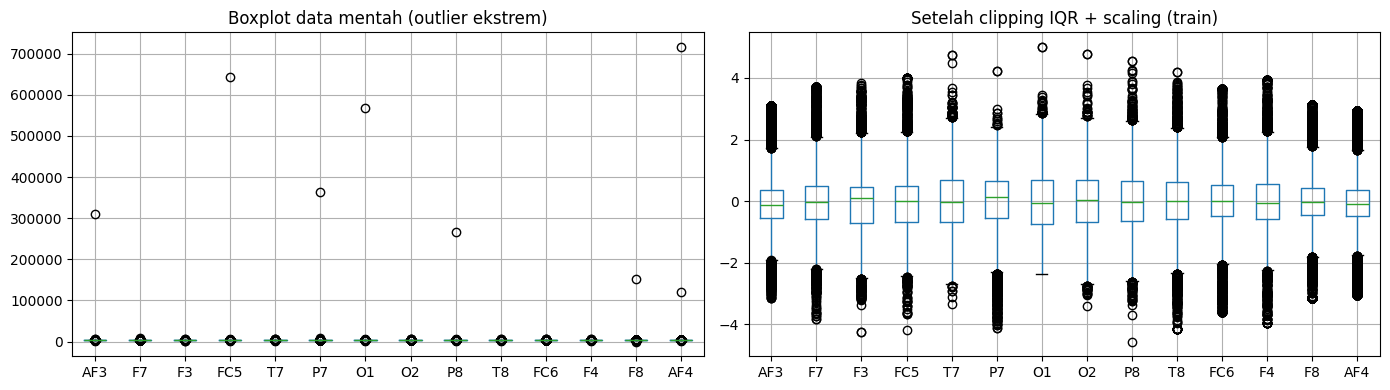

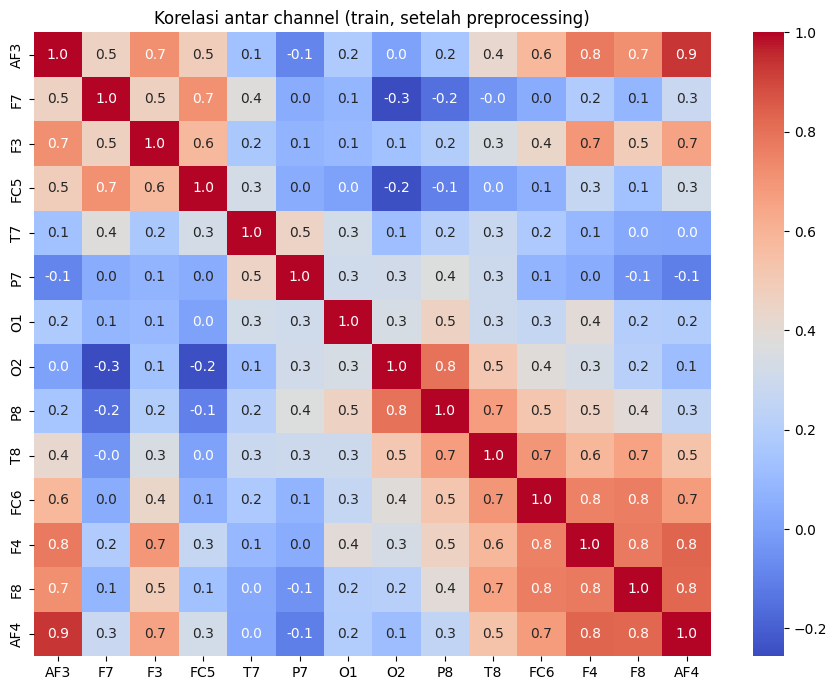

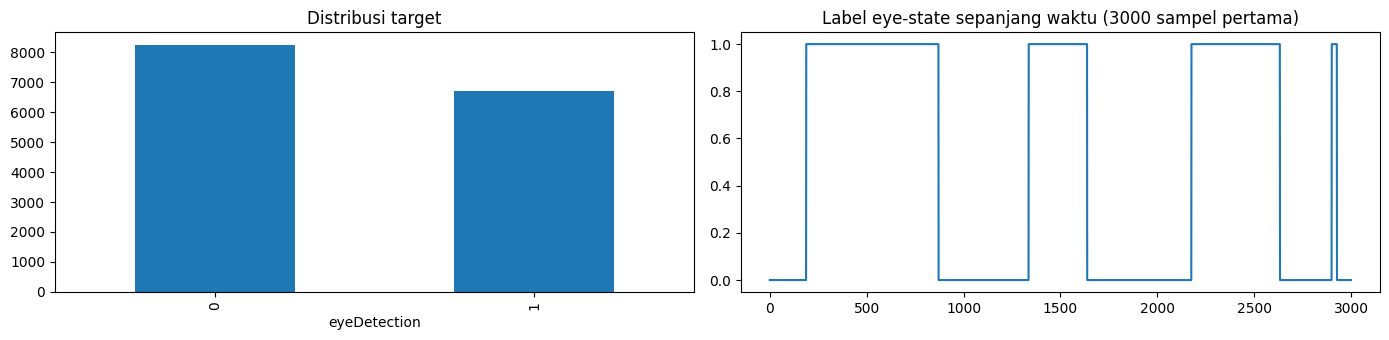

In [ ]:
print(df.describe().T.round(2))
print("\nDistribusi target (0=open, 1=closed):\n", df[TARGET].value_counts(normalize=True).round(3))
for k, v in parts.items():
    print(f"{k:5s} n={len(v):5d}  rasio eye-closed={v[TARGET].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[FEATURES].boxplot(ax=ax[0]); ax[0].set_title("Boxplot data mentah (outlier ekstrem)")
pd.DataFrame(XS["train"], columns=FEATURES).boxplot(ax=ax[1]); ax[1].set_title("Setelah clipping IQR + scaling (train)")
plt.tight_layout(); plt.savefig(OUT/"eda_boxplot.png", dpi=120); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(XS["train"], columns=FEATURES).corr(), cmap="coolwarm", annot=True, fmt=".1f")
plt.title("Korelasi antar channel (train, setelah preprocessing)"); plt.tight_layout()
plt.savefig(OUT/"eda_corr.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], title="Distribusi target")
ax[1].plot(df[TARGET].values[:3000]); ax[1].set_title("Label eye-state sepanjang waktu (3000 sampel pertama)")
plt.tight_layout(); plt.savefig(OUT/"eda_target.png", dpi=120); plt.show()
df.describe().T.to_csv(OUT/"eda_stats.csv")